# Cognifyz Data Analysis Internship - Level 2
**Name:** Gaurav Govind Nikam
**Dataset:** Restaurant dataset (Dataset_.csv)

Tasks in this level:
1. Restaurant Ratings
2. Cuisine Combination
3. Geographic Analysis
4. Restaurant Chains

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')

In [2]:
df = pd.read_csv('Dataset_.csv', encoding='utf-8-sig')
print(df.shape)
df.head()

(9551, 21)


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


In [3]:
df.isnull().sum()

Restaurant ID           0
Restaurant Name         0
Country Code            0
City                    0
Address                 0
Locality                0
Locality Verbose        0
Longitude               0
Latitude                0
Cuisines                9
Average Cost for two    0
Currency                0
Has Table booking       0
Has Online delivery     0
Is delivering now       0
Switch to order menu    0
Price range             0
Aggregate rating        0
Rating color            0
Rating text             0
Votes                   0
dtype: int64

## Task 1 - Restaurant Ratings
- Distribution of aggregate rating and the most common rating range
- Average number of votes per restaurant

In [4]:
df['Aggregate rating'].describe()

count    9551.000000
mean        2.666370
std         1.516378
min         0.000000
25%         2.500000
50%         3.200000
75%         3.700000
max         4.900000
Name: Aggregate rating, dtype: float64

In [5]:
print('Restaurants with 0 rating:', (df['Aggregate rating'] == 0).sum())
df['Rating text'].value_counts()

Restaurants with 0 rating: 2148


Rating text
Average      3737
Not rated    2148
Good         2100
Very Good    1079
Excellent     301
Poor          186
Name: count, dtype: int64

There are 2148 restaurants with rating 0 and their rating text is "Not rated". So 0 is not a real rating, it means nobody has rated them yet. I will show them separately in the chart.

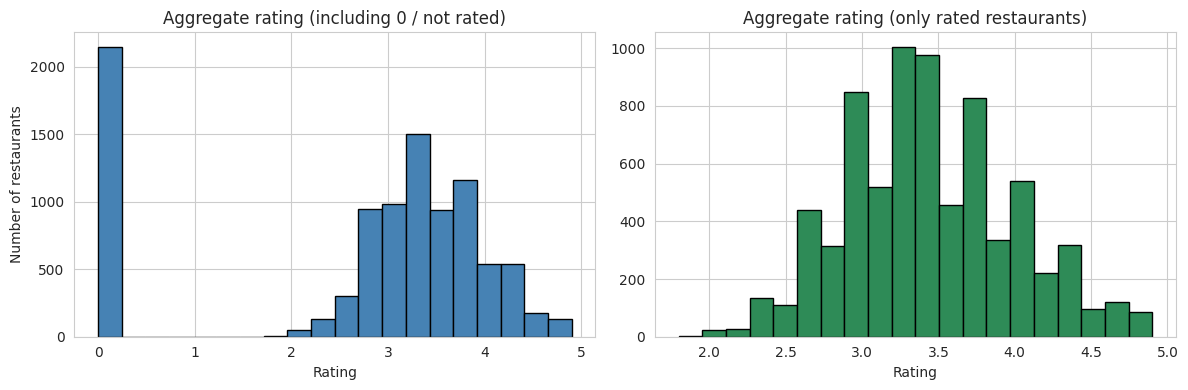

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# all values including 0
axes[0].hist(df['Aggregate rating'], bins=20, color='steelblue', edgecolor='black')
axes[0].set_title('Aggregate rating (including 0 / not rated)')
axes[0].set_xlabel('Rating')
axes[0].set_ylabel('Number of restaurants')

# only rated
axes[1].hist(df[df['Aggregate rating'] > 0]['Aggregate rating'], bins=20, color='seagreen', edgecolor='black')
axes[1].set_title('Aggregate rating (only rated restaurants)')
axes[1].set_xlabel('Rating')

plt.tight_layout()
plt.show()

In [7]:
# grouping ratings in ranges
rated = df[df['Aggregate rating'] > 0].copy()
bins = [0, 1, 2, 3, 4, 5]
labels = ['0-1', '1-2', '2-3', '3-4', '4-5']
rated['rating_range'] = pd.cut(rated['Aggregate rating'], bins=bins, labels=labels)

range_counts = rated['rating_range'].value_counts().sort_index()
range_pct = (range_counts / len(rated) * 100).round(2)
pd.DataFrame({'Restaurants': range_counts, 'Percentage (%)': range_pct})

,Restaurants,Percentage (%)
rating_range,,
0-1,0,0.00
1-2,10,0.14
2-3,1891,25.54
3-4,4388,59.27
4-5,1114,15.05


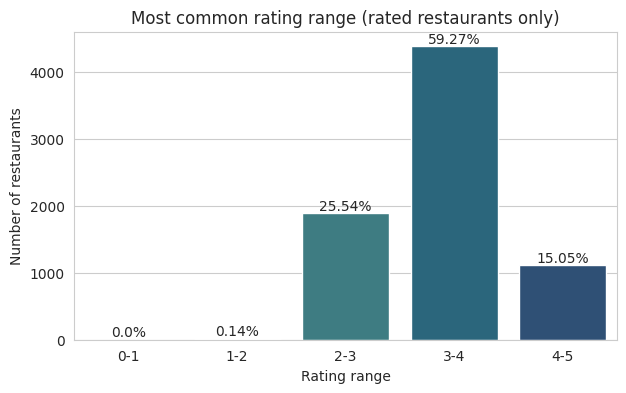

In [8]:
plt.figure(figsize=(7, 4))
ax = sns.barplot(x=range_counts.index, y=range_counts.values, palette='crest')
for i, v in enumerate(range_pct.values):
    ax.text(i, range_counts.values[i] + 50, f'{v}%', ha='center')
plt.title('Most common rating range (rated restaurants only)')
plt.xlabel('Rating range')
plt.ylabel('Number of restaurants')
plt.show()

In [9]:
avg_votes = df['Votes'].mean()
median_votes = df['Votes'].median()
print('Average votes per restaurant:', round(avg_votes, 2))
print('Median votes per restaurant :', median_votes)
print('Max votes:', df['Votes'].max())

Average votes per restaurant: 156.91
Median votes per restaurant : 31.0
Max votes: 10934


**Observation:**
- Out of 7403 rated restaurants, the most common rating range is **3-4** (4388 restaurants, ~59%). Then **2-3** (1891, ~25.5%) and **4-5** (1114, ~15%). Very few restaurants are rated below 2 (only 10).
- 2148 restaurants (about 22.5% of the data) are "Not rated" with 0 rating.
- Average votes per restaurant is **156.91** but the median is only **31**. This means a few very popular restaurants have thousands of votes and pull the average up, while most restaurants have very few votes. So median is the better number to look at here.

## Task 2 - Cuisine Combination
- Most common combinations of cuisines
- Do some combinations get higher ratings?

In [10]:
cuis = df.dropna(subset=['Cuisines']).copy()

# sorting the cuisines inside each cell so that "Chinese, North Indian" and "North Indian, Chinese" are treated as the same combo
cuis['combo'] = cuis['Cuisines'].apply(lambda x: ', '.join(sorted([c.strip() for c in x.split(',')])))
combo_counts = cuis['combo'].value_counts()
combo_counts.head(10)

combo
North Indian                      936
Chinese, North Indian             616
Mughlai, North Indian             394
Chinese                           354
Fast Food                         354
Chinese, Mughlai, North Indian    306
Cafe                              299
Bakery                            218
Bakery, Desserts                  181
Chinese, Fast Food                159
Name: count, dtype: int64

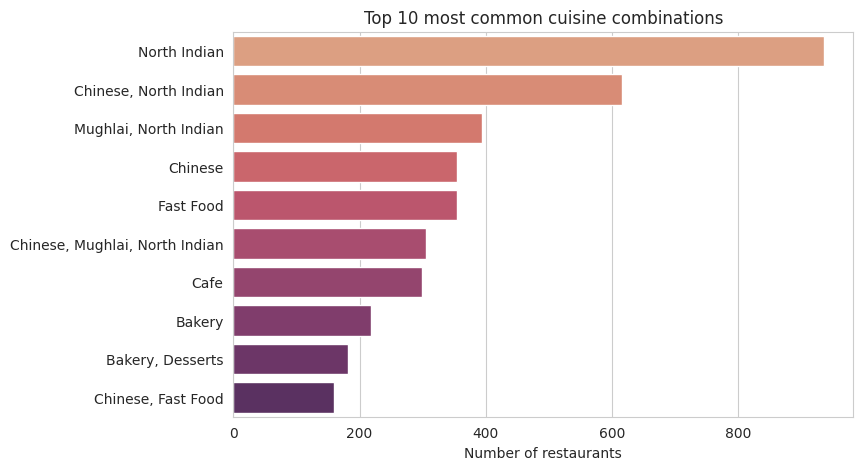

In [11]:
plt.figure(figsize=(8, 5))
top10 = combo_counts.head(10)
sns.barplot(x=top10.values, y=top10.index, palette='flare')
plt.title('Top 10 most common cuisine combinations')
plt.xlabel('Number of restaurants')
plt.ylabel('')
plt.show()

In [12]:
# also checking combos of exactly 2 cuisines, because single cuisines are not really a "combination"
cuis['num_cuisines'] = cuis['Cuisines'].str.split(',').apply(len)
two = cuis[cuis['num_cuisines'] == 2]['combo'].value_counts()
two.head(10)

combo
Chinese, North Indian      616
Mughlai, North Indian      394
Bakery, Desserts           181
Chinese, Fast Food         159
Fast Food, Pizza           142
Mithai, Street Food        134
Fast Food, North Indian    120
Bakery, Fast Food          117
Desserts, Ice Cream        109
Burger, Fast Food           99
Name: count, dtype: int64

In [13]:
# ratings of combos (only rated restaurants, and combos with at least 20 restaurants so the average is not random)
rated_c = cuis[cuis['Aggregate rating'] > 0]
combo_rating = rated_c.groupby('combo')['Aggregate rating'].agg(['mean', 'count'])
combo_rating = combo_rating[combo_rating['count'] >= 20].round(2)
combo_rating = combo_rating.sort_values('mean', ascending=False)

print('Combos with 20+ rated restaurants:', len(combo_rating))
print('\nHighest rated:')
display(combo_rating.head(8))
print('Lowest rated:')
display(combo_rating.tail(5))

Combos with 20+ rated restaurants: 52

Highest rated:


,mean,count
combo,,
"Japanese, Sushi",4.06,20
Italian,3.95,50
American,3.92,29
Mexican,3.85,34
Continental,3.74,20
"Italian, Pizza",3.74,42
"Continental, Italian, North Indian",3.68,29
"Chinese, Continental, Italian, North Indian",3.61,37


Lowest rated:


,mean,count
combo,,
"Biryani, North Indian",3.06,26
"Fast Food, Pizza",3.03,121
"Chinese, South Indian",3.03,33
"American, Fast Food, Healthy Food, Salad",3.00,61
"Fast Food, Raw Meats",2.99,27


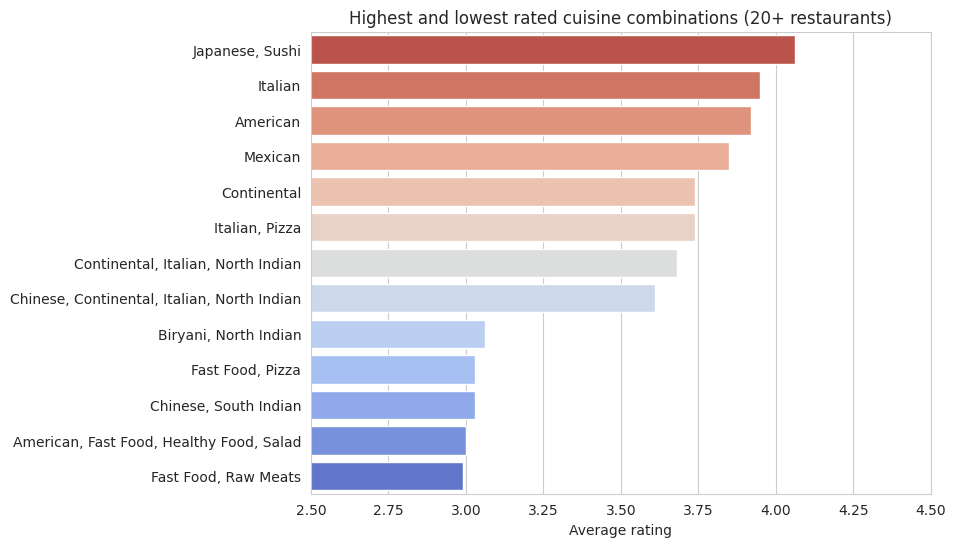

In [14]:
plt.figure(figsize=(8, 6))
show = pd.concat([combo_rating.head(8), combo_rating.tail(5)])
sns.barplot(x=show['mean'], y=show.index, palette='coolwarm_r')
plt.title('Highest and lowest rated cuisine combinations (20+ restaurants)')
plt.xlabel('Average rating')
plt.ylabel('')
plt.xlim(2.5, 4.5)
plt.show()

**Observation:**
- The most common cuisine combo is just **North Indian** alone (936), then **Chinese + North Indian** (616) and **Mughlai + North Indian** (394). Among 2-cuisine combos, Chinese + North Indian is the number 1.
- Yes, ratings do change by combination. **Japanese + Sushi** (4.06), **Italian** (3.95), **American** (3.92) and **Mexican** (3.85) have the highest averages.
- The lowest are things like **Fast Food + Raw Meats** (2.99), **American/Fast Food/Healthy Food/Salad** (3.00), and **Fast Food + Pizza** (3.03). Fast food related combinations are generally at the bottom.
- The most common combinations (North Indian, Chinese) are mostly mid-rated, so being common does not mean being highly rated. Specialised / international cuisines score better on average.

## Task 3 - Geographic Analysis
- Plot restaurant locations using longitude and latitude
- Find patterns / clusters

In [15]:
df[['Longitude', 'Latitude']].describe()

,Longitude,Latitude
count,9551.000000,9551.000000
mean,64.126574,25.854381
std,41.467058,11.007935
min,-157.948486,-41.330428
25%,77.081343,28.478713
50%,77.191964,28.570469
75%,77.282006,28.642758
max,174.832089,55.976980


In [16]:
print('Rows with Longitude = 0 and Latitude = 0:', ((df['Longitude'] == 0) & (df['Latitude'] == 0)).sum())
df[(df['Longitude'] == 0) & (df['Latitude'] == 0)][['Restaurant Name', 'City']].head()

Rows with Longitude = 0 and Latitude = 0: 497


,Restaurant Name,City
625,Rangrezz Restaurant,Agra
629,MoMo Cafe,Agra
632,G Thal,Agra
638,Bon Barbecue,Agra
639,Chapter 1 Cafe,Agra


497 rows have longitude and latitude both as 0, which is a point in the sea near Africa, so these are missing coordinates and not real locations. I will remove them only for the map.

In [17]:
geo = df[~((df['Longitude'] == 0) & (df['Latitude'] == 0))].copy()
print('Restaurants that can be plotted:', len(geo))

Restaurants that can be plotted: 9054


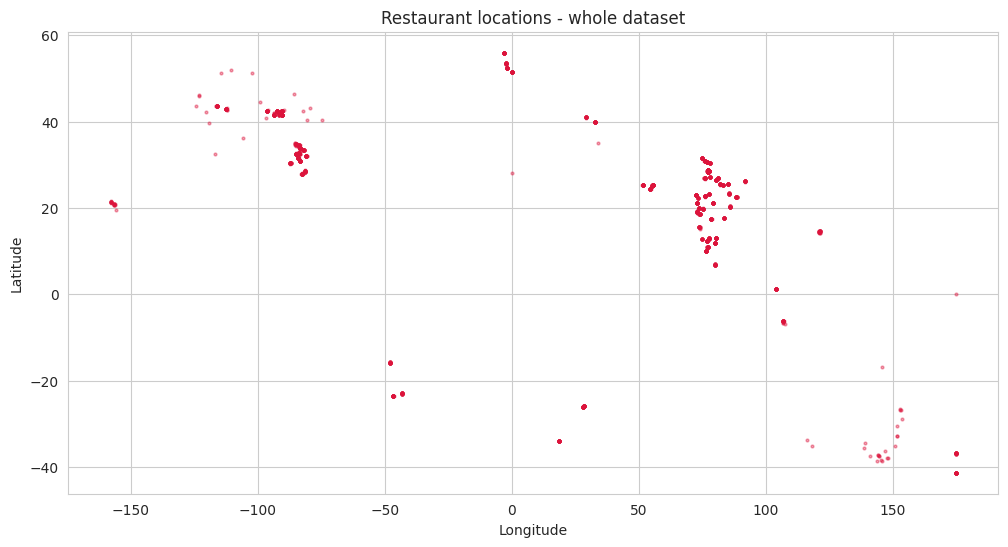

In [18]:
plt.figure(figsize=(12, 6))
plt.scatter(geo['Longitude'], geo['Latitude'], s=4, alpha=0.4, color='crimson')
plt.title('Restaurant locations - whole dataset')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

In [19]:
# country wise count (country code)
df['Country Code'].value_counts()

Country Code
1      8652
216     434
215      80
30       60
214      60
189      60
148      40
208      34
14       24
162      22
94       21
184      20
166      20
191      20
37        4
Name: count, dtype: int64

Restaurants in India (with location): 8157


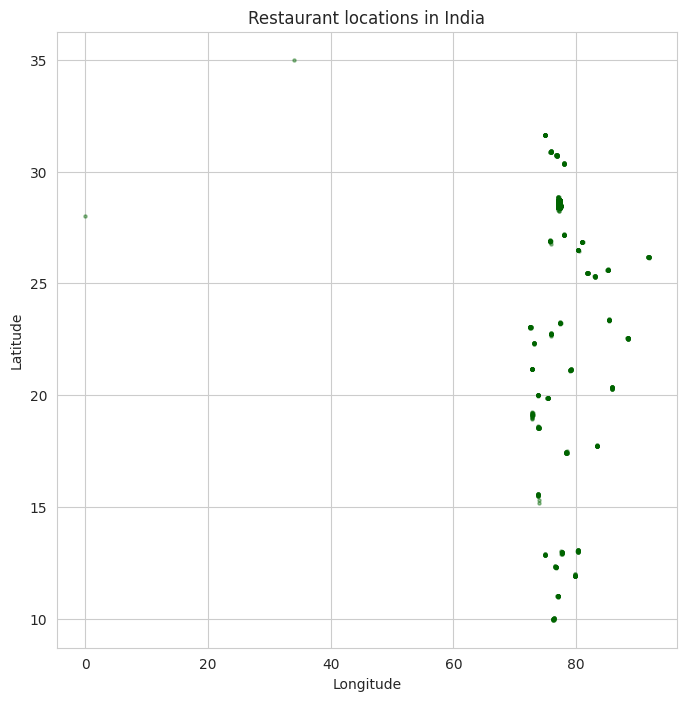

In [20]:
# India is country code 1, zooming only into India
india = geo[geo['Country Code'] == 1]
print('Restaurants in India (with location):', len(india))

plt.figure(figsize=(8, 8))
plt.scatter(india['Longitude'], india['Latitude'], s=5, alpha=0.4, color='darkgreen')
plt.title('Restaurant locations in India')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

Restaurants in the Delhi NCR box: 7549


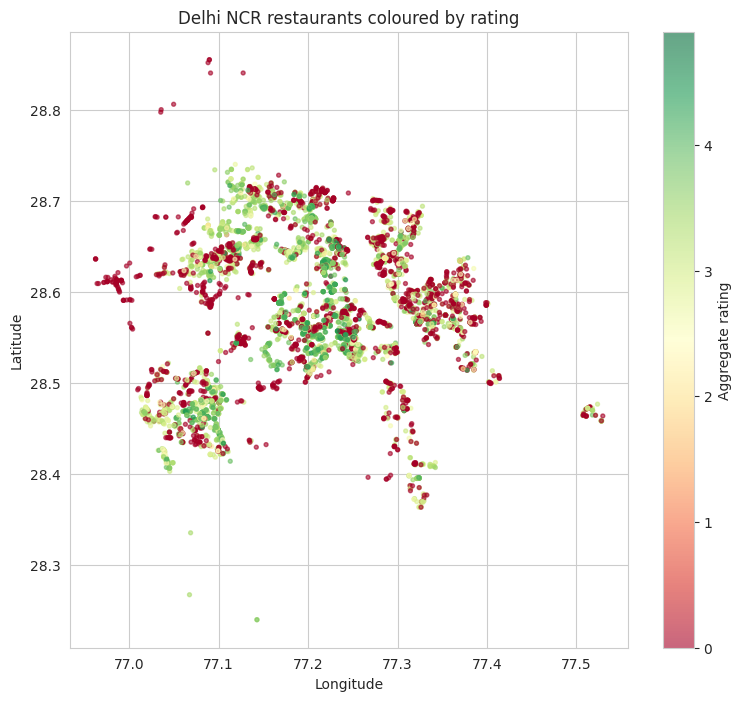

In [21]:
# most of the restaurants are in Delhi NCR, so zooming on that area
ncr = india[(india['Longitude'].between(76.8, 77.7)) & (india['Latitude'].between(28.2, 28.95))]
print('Restaurants in the Delhi NCR box:', len(ncr))

plt.figure(figsize=(9, 8))
sc = plt.scatter(ncr['Longitude'], ncr['Latitude'], c=ncr['Aggregate rating'], cmap='RdYlGn', s=8, alpha=0.6)
plt.colorbar(sc, label='Aggregate rating')
plt.title('Delhi NCR restaurants coloured by rating')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

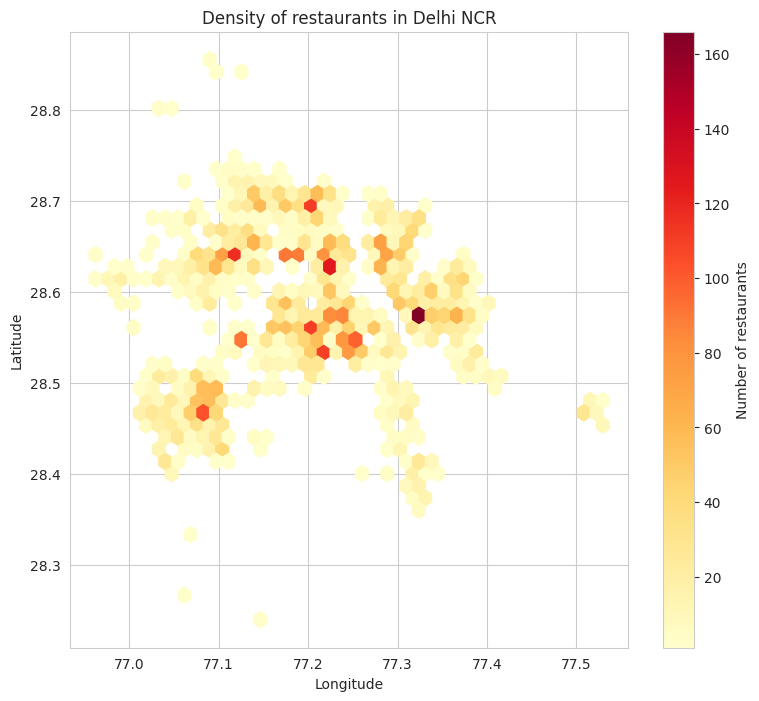

In [22]:
# density view to see the clusters better
plt.figure(figsize=(9, 8))
plt.hexbin(ncr['Longitude'], ncr['Latitude'], gridsize=40, cmap='YlOrRd', mincnt=1)
plt.colorbar(label='Number of restaurants')
plt.title('Density of restaurants in Delhi NCR')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

In [23]:
# which localities have the most restaurants
df['Locality'].value_counts().head(10)

Locality
Connaught Place        122
Rajouri Garden          99
Shahdara                87
Defence Colony          86
Malviya Nagar           85
Pitampura               85
Mayur Vihar Phase 1     84
Rajinder Nagar          81
Safdarjung              80
Satyaniketan            79
Name: count, dtype: int64

**Observation:**
- On the world plot, the restaurants form separate small groups on different continents (India, USA, UK, UAE, Brazil, New Zealand, South Africa etc.), but the biggest group by far is **India** (8652 restaurants, around 90% of the data).
- Inside India almost all points are in **Delhi NCR** (New Delhi, Gurgaon, Noida, Faridabad, Ghaziabad). Other Indian cities appear as small separate dots.
- In the NCR density map, the darkest (densest) spot is in the Noida side (east), and there is another dense area around central Delhi (Connaught Place region). Gurgaon shows up as a separate patch in the south-west.
- Top localities like Connaught Place are busy dining hubs, so restaurants are clustered in markets and commercial areas instead of being spread evenly.
- Colour by rating shows that ratings are mixed everywhere, so a high number of restaurants in an area does not tell anything about quality there.

*Note: I used simple scatter and hexbin plots with matplotlib for the map.*

## Task 4 - Restaurant Chains
- Identify chains present in the dataset
- Analyse ratings and popularity of chains

In [24]:
# if the same restaurant name appears at many locations I am treating it as a chain
name_counts = df['Restaurant Name'].value_counts()
name_counts.head(15)

Restaurant Name
Cafe Coffee Day     83
Domino's Pizza      79
Subway              63
Green Chick Chop    51
McDonald's          48
Keventers           34
Pizza Hut           30
Giani               29
Baskin Robbins      28
Barbeque Nation     26
Dunkin' Donuts      22
Giani's             22
Barista             22
Pind Balluchi       20
Costa Coffee        20
Name: count, dtype: int64

In [25]:
# chain = name with 10 or more outlets (my own cutoff)
chains = name_counts[name_counts >= 10]
print('Number of chains (10+ outlets):', len(chains))
print('Restaurants that belong to these chains:', chains.sum())

Number of chains (10+ outlets): 40
Restaurants that belong to these chains: 946


In [26]:
chain_df = df[df['Restaurant Name'].isin(chains.index)]

chain_stats = chain_df.groupby('Restaurant Name').agg(
    outlets=('Restaurant ID', 'count'),
    avg_votes=('Votes', 'mean'),
    total_votes=('Votes', 'sum')
)

# rating only from rated outlets
chain_rating = chain_df[chain_df['Aggregate rating'] > 0].groupby('Restaurant Name')['Aggregate rating'].mean()
chain_stats['avg_rating'] = chain_rating
chain_stats = chain_stats.round(2).sort_values('outlets', ascending=False)
chain_stats

,outlets,avg_votes,total_votes,avg_rating
Restaurant Name,,,,
Cafe Coffee Day,83,29.25,2428,3.00
Domino's Pizza,79,84.09,6643,2.93
Subway,63,97.21,6124,3.00
Green Chick Chop,51,18.90,964,3.10
McDonald's,48,110.23,5291,3.41
Keventers,34,37.15,1263,3.37
Pizza Hut,30,165.37,4961,3.43
Giani,29,29.45,854,3.25
Baskin Robbins,28,15.29,428,3.26


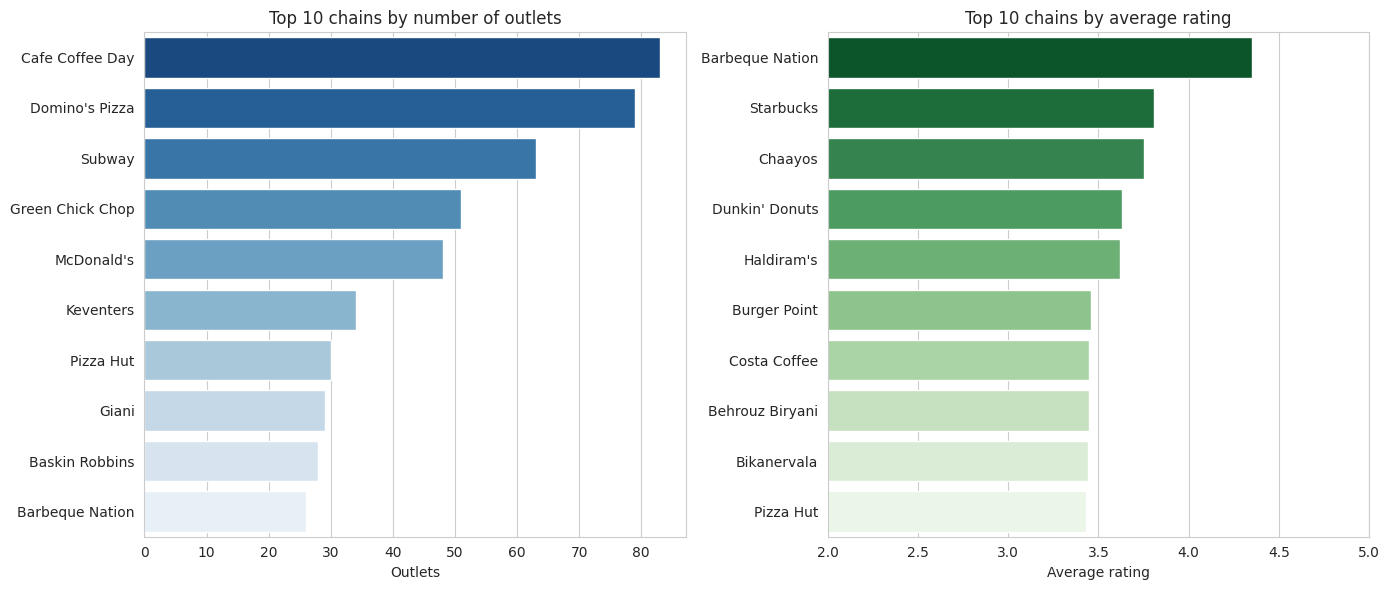

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

top_outlets = chain_stats.head(10)
sns.barplot(x=top_outlets['outlets'], y=top_outlets.index, ax=axes[0], palette='Blues_r')
axes[0].set_title('Top 10 chains by number of outlets')
axes[0].set_xlabel('Outlets')
axes[0].set_ylabel('')

top_rating = chain_stats.sort_values('avg_rating', ascending=False).head(10)
sns.barplot(x=top_rating['avg_rating'], y=top_rating.index, ax=axes[1], palette='Greens_r')
axes[1].set_title('Top 10 chains by average rating')
axes[1].set_xlabel('Average rating')
axes[1].set_ylabel('')
axes[1].set_xlim(2, 5)

plt.tight_layout()
plt.show()

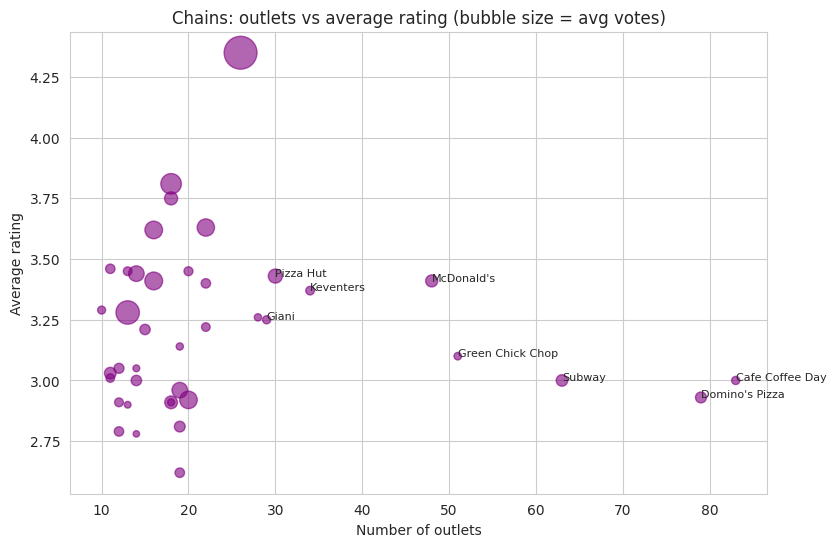

In [28]:
# popularity (votes) vs rating
plt.figure(figsize=(9, 6))
plt.scatter(chain_stats['outlets'], chain_stats['avg_rating'], s=chain_stats['avg_votes'] / 2 + 20, alpha=0.6, color='purple')
for name, row in chain_stats.head(8).iterrows():
    plt.annotate(name, (row['outlets'], row['avg_rating']), fontsize=8)
plt.title('Chains: outlets vs average rating (bubble size = avg votes)')
plt.xlabel('Number of outlets')
plt.ylabel('Average rating')
plt.show()

In [29]:
print('Most popular chains by average votes per outlet:')
chain_stats.sort_values('avg_votes', ascending=False).head(5)

Most popular chains by average votes per outlet:


,outlets,avg_votes,total_votes,avg_rating
Restaurant Name,,,,
Barbeque Nation,26,1082.38,28142,4.35
Karim's,13,529.08,6878,3.28
Starbucks,18,396.61,7139,3.81
Burger King,16,288.56,4617,3.41
Haldiram's,16,282.81,4525,3.62


**Observation:**
- Yes, there are many restaurant chains in the dataset. The biggest are **Cafe Coffee Day (83 outlets)**, **Domino's Pizza (79)**, **Subway (63)**, **Green Chick Chop (51)** and **McDonald's (48)**.
- The biggest chains are not the best rated. Domino's (about 2.9), Cafe Coffee Day (3.0) and Subway (3.0) are all around 3, which is average.
- **Barbeque Nation** has fewer outlets (26) but a high average rating (~4.35) and a very high number of votes (over 1000 per outlet), so it is the most popular and best rated chain here.
- So having more outlets does not mean better ratings, quality chains with fewer outlets (like Barbeque Nation) do better.

---
**Level 2 completed.**